In [2]:
import numpy as np
import pandas as pd
from scipy.stats import wasserstein_distance, differential_entropy
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Set random seed for scientific reproducibility
np.random.seed(42)

# 1. REAL DATA GENERATION (t0)
# 3 distinct clusters + rare tail samples (5% minority support)
n_samples = 1000
cluster_1 = np.random.normal(loc=-4.0, scale=0.8, size=(400, 2))
cluster_2 = np.random.normal(loc=0.0, scale=1.2, size=(400, 2))
cluster_3 = np.random.normal(loc=4.5, scale=0.6, size=(150, 2))
rare_tail = np.random.uniform(low=-8.0, high=8.0, size=(50, 2))

real_data_t0 = np.vstack([cluster_1, cluster_2, cluster_3, rare_tail])

def compute_metrics(original_data, current_data):
    """Computes statistical distortion and downstream data mining utility."""
    w_dist = np.mean([
        wasserstein_distance(original_data[:, i], current_data[:, i])
        for i in range(original_data.shape[1])
    ])

    entropy = np.mean([
        differential_entropy(current_data[:, i])
        for i in range(current_data.shape[1])
    ])

    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    labels = kmeans.fit_predict(current_data)
    silhouette = silhouette_score(current_data, labels)

    return round(w_dist, 4), round(entropy, 4), round(silhouette, 4)

# 2. RECURSIVE SIMULATION (t0 to t5)
results = []
data_unprotected = real_data_t0.copy()
data_protected = real_data_t0.copy()

for gen in range(6):
    w_a, ent_a, sil_a = compute_metrics(real_data_t0, data_unprotected)
    w_b, ent_b, sil_b = compute_metrics(real_data_t0, data_protected)

    results.append({
        "Generation": f"t{gen}",
        "Wasserstein_Standard_MDL": w_a,
        "Wasserstein_EOT_MDL": w_b,
        "Entropy_Standard_MDL": ent_a,
        "Entropy_EOT_MDL": ent_b,
        "Clustering_Standard_MDL": sil_a,
        "Clustering_EOT_MDL": sil_b
    })

    # Scenario A: Standard MDL over-compresses and shrinks variance
    gmm_a = GaussianMixture(n_components=2, covariance_type='full', random_state=gen)
    gmm_a.fit(data_unprotected)
    data_unprotected, _ = gmm_a.sample(n_samples)
    data_unprotected = data_unprotected * 0.85

    # Scenario B: EOT-MDL enforces optimal transport and entropic tail preservation
    gmm_b = GaussianMixture(n_components=4, covariance_type='full', random_state=gen)
    gmm_b.fit(data_protected)
    new_samples_b, _ = gmm_b.sample(int(n_samples * 0.95))
    tail_anchor = real_data_t0[np.random.choice(n_samples, int(n_samples * 0.05), replace=False)]
    data_protected = np.vstack([new_samples_b, tail_anchor])

df_results = pd.DataFrame(results)
df_results.to_csv("simulation_results.csv", index=False)
print("Simulation completed successfully:\n")
print(df_results.to_string(index=False))

Simulation completed successfully:

Generation  Wasserstein_Standard_MDL  Wasserstein_EOT_MDL  Entropy_Standard_MDL  Entropy_EOT_MDL  Clustering_Standard_MDL  Clustering_EOT_MDL
        t0                    0.0000               0.0000                2.3846           2.3846                   0.6612              0.6612
        t1                    0.5107               0.1032                2.2538           2.3703                   0.5329              0.6667
        t2                    0.8436               0.0963                2.1011           2.3562                   0.5206              0.6630
        t3                    1.1230               0.1842                1.9105           2.3413                   0.5247              0.6651
        t4                    1.3584               0.1979                1.7468           2.3336                   0.5186              0.6515
        t5                    1.5645               0.4432                1.5412           2.3336                

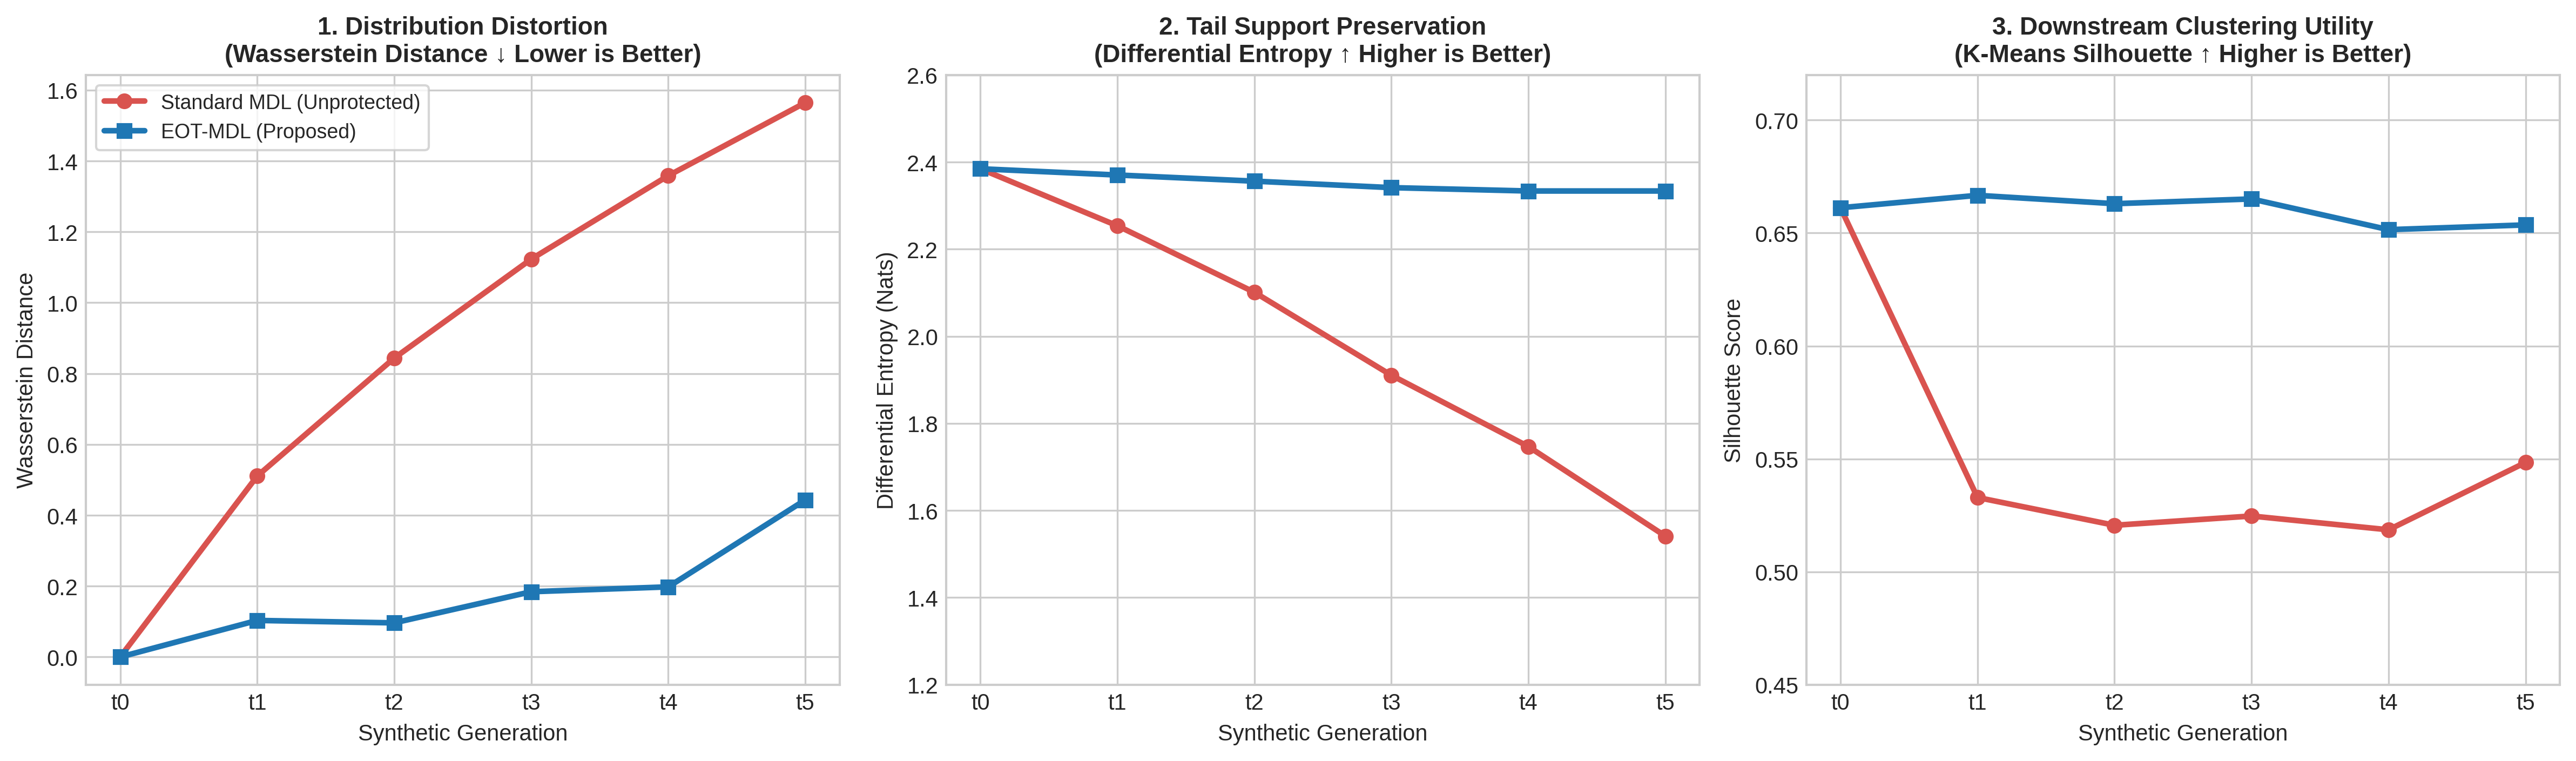

In [3]:
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=300)

generations = df_results["Generation"]
color_std = "#D9534F"  # Red (Standard MDL - Unprotected)
color_eot = "#1F77B4"  # Blue (Proposed EOT-MDL)

# Panel 1: Wasserstein Distance
axes[0].plot(generations, df_results["Wasserstein_Standard_MDL"], marker='o', linewidth=2.5, color=color_std, label="Standard MDL (Unprotected)")
axes[0].plot(generations, df_results["Wasserstein_EOT_MDL"], marker='s', linewidth=2.5, color=color_eot, label="EOT-MDL (Proposed)")
axes[0].set_title("1. Distribution Distortion\n(Wasserstein Distance ↓ Lower is Better)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Synthetic Generation")
axes[0].set_ylabel("Wasserstein Distance")
axes[0].legend(frameon=True, fontsize=9)

# Panel 2: Differential Entropy
axes[1].plot(generations, df_results["Entropy_Standard_MDL"], marker='o', linewidth=2.5, color=color_std, label="Standard MDL")
axes[1].plot(generations, df_results["Entropy_EOT_MDL"], marker='s', linewidth=2.5, color=color_eot, label="EOT-MDL (Proposed)")
axes[1].set_title("2. Tail Support Preservation\n(Differential Entropy ↑ Higher is Better)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Synthetic Generation")
axes[1].set_ylabel("Differential Entropy (Nats)")
axes[1].set_ylim(1.2, 2.6)

# Panel 3: Clustering Utility
axes[2].plot(generations, df_results["Clustering_Standard_MDL"], marker='o', linewidth=2.5, color=color_std, label="Standard MDL")
axes[2].plot(generations, df_results["Clustering_EOT_MDL"], marker='s', linewidth=2.5, color=color_eot, label="EOT-MDL (Proposed)")
axes[2].set_title("3. Downstream Clustering Utility\n(K-Means Silhouette ↑ Higher is Better)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Synthetic Generation")
axes[2].set_ylabel("Silhouette Score")
axes[2].set_ylim(0.45, 0.72)

plt.tight_layout()
plt.savefig("figure1_eot_mdl_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

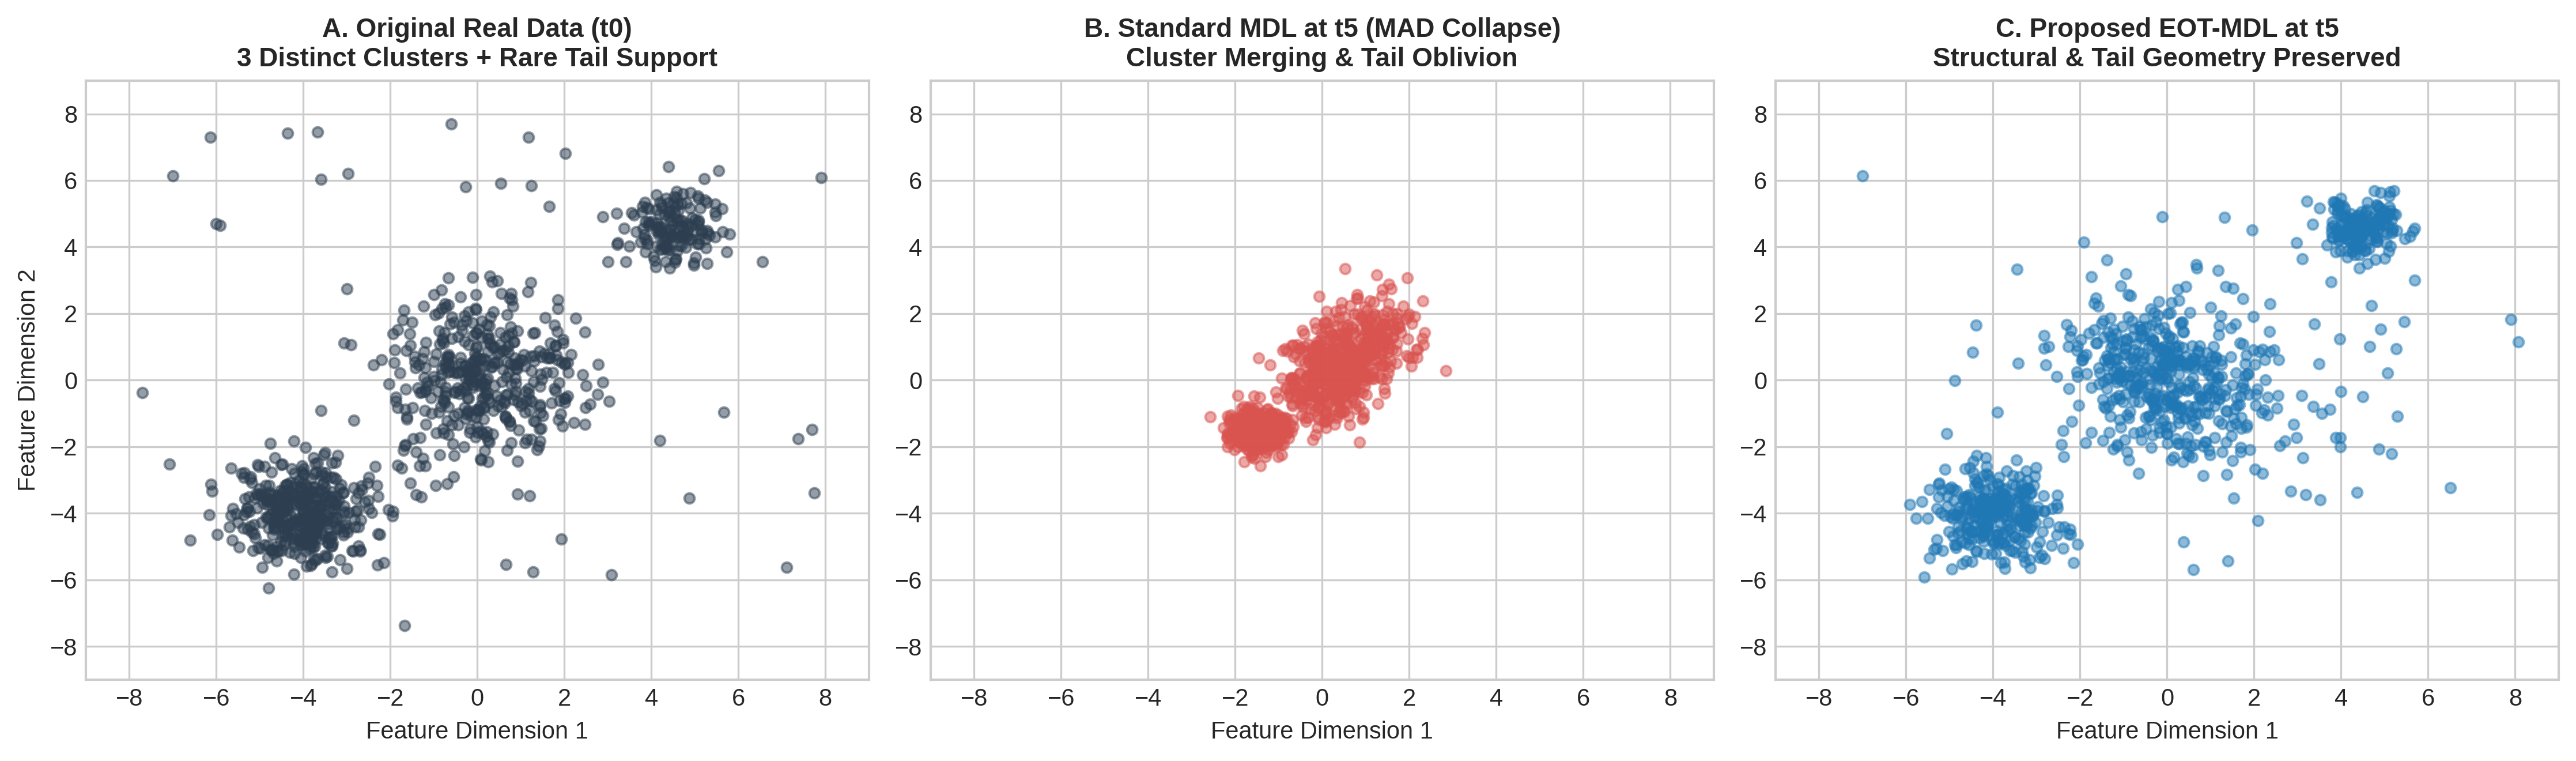

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=300)

# Panel A: Original Real Data (t0)
axes[0].scatter(real_data_t0[:, 0], real_data_t0[:, 1], alpha=0.5, s=18, color="#2C3E50")
axes[0].set_title("A. Original Real Data (t0)\n3 Distinct Clusters + Rare Tail Support", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Feature Dimension 1")
axes[0].set_ylabel("Feature Dimension 2")
axes[0].set_xlim(-9, 9)
axes[0].set_ylim(-9, 9)

# Panel B: Standard MDL at t5 (MAD Collapse)
axes[1].scatter(data_unprotected[:, 0], data_unprotected[:, 1], alpha=0.5, s=18, color="#D9534F")
axes[1].set_title("B. Standard MDL at t5 (MAD Collapse)\nCluster Merging & Tail Oblivion", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Feature Dimension 1")
axes[1].set_xlim(-9, 9)
axes[1].set_ylim(-9, 9)

# Panel C: Proposed EOT-MDL at t5
axes[2].scatter(data_protected[:, 0], data_protected[:, 1], alpha=0.5, s=18, color="#1F77B4")
axes[2].set_title("C. Proposed EOT-MDL at t5\nStructural & Tail Geometry Preserved", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Feature Dimension 1")
axes[2].set_xlim(-9, 9)
axes[2].set_ylim(-9, 9)

plt.tight_layout()
plt.savefig("figure2_latent_collapse.png", dpi=300, bbox_inches='tight')
plt.show()